In [37]:
%load_ext autoreload
%autoreload 2

import glob
import math

import torch
import torch.nn as nn

import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
print("TensorFlow version: ", tf.__version__)

from ultralytics.utils.tal import make_anchors

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
TensorFlow version:  2.13.1


In [38]:
tst_img_paths = sorted(glob.glob("../datasets/position_db_pose/images/test/*.jpg"))
len(tst_img_paths)

490

In [39]:
class DFL(nn.Module):
    """
    Integral module of Distribution Focal Loss (DFL).

    Proposed in Generalized Focal Loss https://ieeexplore.ieee.org/document/9792391
    """

    def __init__(self, c1=16, num_classes=1):
        """Initialize a convolutional layer with a given number of input channels."""
        super().__init__()
        self.conv = nn.Conv2d(c1, 1, 1, bias=False).requires_grad_(False)
        x = torch.arange(c1, dtype=torch.float)
        self.conv.weight.data[:] = nn.Parameter(x.view(1, c1, 1, 1))
        self.c1 = c1
        self.sigm = nn.Sigmoid()
        self.num_classes = num_classes

    def forward(self, x0, x1, x2, x3, x4, x5):
        """Applies a transformer layer on input tensor 'x' and returns a tensor."""
        x = torch.permute(torch.cat([x0, x1, x2], 1), (0, 2, 1))
        y = torch.permute(torch.cat([x3, x4, x5], 1), (0, 2, 1))
        
        b, c, a = x.shape  # batch, channels, anchors
        out = self.conv(x.view(b, 4, self.c1, a).transpose(2, 1).softmax(1)).view(b, 4, a)
        return out, self.sigm(y)


def dist2bbox_lt_wh(distance, anchor_points, xywh=True, dim=-1):
    """Transform distance(ltrb) to box(xywh or xyxy)."""
    lt, rb = distance.chunk(2, dim)
    x1y1 = anchor_points - lt
    x2y2 = anchor_points + rb
    wh = x2y2 - x1y1
    return torch.cat((x1y1, wh), dim)


class DetectionHead(nn.Module):
    def __init__(self, shapes, img_size=256, num_classes=1):
        super().__init__()
        
        # self.box_idxs = [1, 0, 5, 4, 6, 2]
        # self.kp_idx = 3
        
        mcv = float('-inf')
        self.kp_idx = -1
        for idx, s in enumerate(shapes):
            dim_1 = s[1]
            if dim_1 > mcv:
                mcv = dim_1
                self.kp_idx = idx

        self.box_idxs = [
            i for i, _ in sorted(enumerate(shapes), key=lambda x: (x[1][2] if num_classes > 64 else -x[1][2], -x[1][1]))
        ]
        self.box_idxs.remove(self.kp_idx)

        strides = [
            int(math.sqrt(img_size * img_size / shapes[p][1])) for p in self.box_idxs if shapes[p][2] != 64]
        dims = [(img_size // s, img_size // s) for s in strides]
        fake_feats = [torch.zeros((1, 1, h, w)) for h, w in dims]
        self.anchors, self.strides = (x.transpose(0, 1)
                        for x in make_anchors(fake_feats, strides, 0.5))  # generate anchors and strides

        self.kpt_shape = (shapes[self.kp_idx][-1] // 2, 2)
        reg_max = 16
        self.num_classes = num_classes
        self.dfl = DFL(reg_max, self.num_classes)

    def forward(self, x):
        dbox, y = self.dfl(*[x[i] for i in self.box_idxs])

        dbox = dist2bbox_lt_wh(dbox, self.anchors.unsqueeze(0), xywh=False, dim=1) * self.strides
        dbox = torch.cat((dbox, y), 1)

        kps = torch.permute(x[self.kp_idx], (0, 2, 1))
        kps = (kps * 2.0 + (self.anchors - 0.5)) * self.strides
        # kps[:, 0] = (kps[:, 0] * 2.0 + (self.anchors[0] - 0.5)) * self.strides
        # kps[:, 1] = (kps[:, 1] * 2.0 + (self.anchors[1] - 0.5)) * self.strides
        
        return torch.cat([dbox, kps], 1)

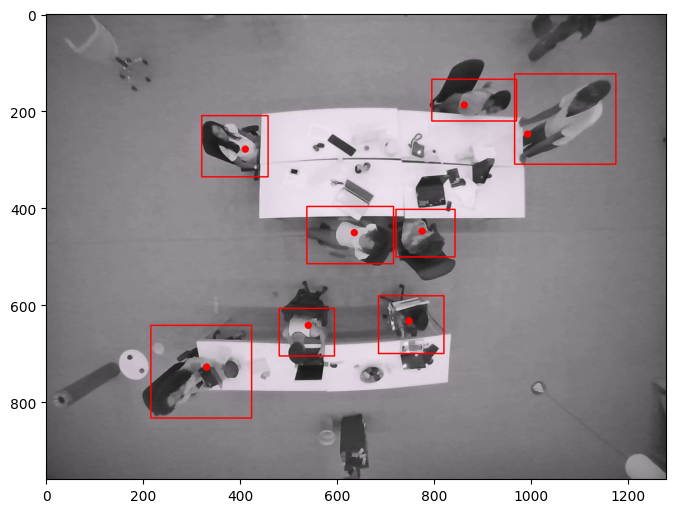

In [40]:
img = cv2.cvtColor(cv2.imread(tst_img_paths[100]), cv2.COLOR_BGR2RGB)

ORIGINAL_H, ORIGIAL_W, _ = img.shape
W = H = 256
RATIO = W / ORIGIAL_W
RESIZED_H = int(ORIGINAL_H * RATIO)
IMG_SHAPE = (1, H, W, 3)
TORCH_IMG_SHAPE = (1, 3, H, W)

conf = 0.1
iou = 0.7
agnostic_nms = False
max_det = 300
classes =None
############################

# Initialize the interpreter
interpreter = tf.lite.Interpreter(
    model_path=f"../../researches/leg_position_detectors/yolov8/run_results/model_1_1m_params/positiondb_pose_1m_{W}/weights/best_saved_model/best_full_integer_quant.tflite")
    # model_path=f"../../researches/leg_position_detectors/yolov8/run_results/model_2_5m_params/{W}/weights/best_saved_model/best_full_integer_quant.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

im = np.zeros(IMG_SHAPE, dtype=np.uint8)

resized_img = cv2.resize(img, (W, RESIZED_H))
im[0, :RESIZED_H, :W, :] = resized_img[:, :, :]

details = input_details[0]
interpreter.set_tensor(details['index'], im)
interpreter.invoke()
y = []
for output in output_details:
    x = interpreter.get_tensor(output['index'])
    scale, zero_point = output['quantization']
    x = (x.astype(np.float32) - zero_point) * scale  # re-scale

    y.append(x)

y = [x if isinstance(x, np.ndarray) else x.numpy() for x in y]

# idxs = [4, 1, 5, 3, 0, 2, 6]

# tmp = [y[i] for i in idxs]
# y = tmp

head = DetectionHead([i.shape for i in y], W)

outputs = head.forward([torch.Tensor(i) for i in y]).numpy()

head_outputs = outputs

outputs = np.transpose(outputs, (0, 2, 1))
rows = outputs.shape[1]

boxes = []
scores = []
class_ids = []
kps = []

# Iterate through output to collect bounding boxes, confidence scores, and class IDs
for i in range(rows):
    classes_scores = outputs[0][i][4:5]
    (minScore, maxScore, minClassLoc, (x, maxClassIndex)) = cv2.minMaxLoc(classes_scores)
    if maxScore >= conf:
        box = [
            outputs[0][i][0], # - (0.5 * outputs[0][i][2]),
            outputs[0][i][1], # - (0.5 * outputs[0][i][3]),
            outputs[0][i][2],
            outputs[0][i][3],
        ]
        boxes.append(box)
        scores.append(maxScore)
        class_ids.append(maxClassIndex)
        kps.append(outputs[0][i][5:7])

# Apply NMS (Non-maximum suppression)
result_boxes = cv2.dnn.NMSBoxes(boxes, scores, conf, iou, 0.5)

detections = []

# Iterate through NMS results to draw bounding boxes and labels
for i in range(len(result_boxes)):
    index = result_boxes[i]
    box = boxes[index]
    
    detections.append([*box, scores[index], class_ids[index], *kps[index]])
    
detections = np.array(detections)

for box in detections:
    cv2.rectangle(img, (box[:2] / RATIO).astype(int), ((box[:2].astype(int) + box[2:4]) / RATIO).astype(int) , (255, 0, 0), 2)

for p in detections:
    cv2.circle(img, (p[-2:] // RATIO).astype(int), 4, (255, 0, 0), 5)

plt.figure(figsize=(8, 8))
plt.imshow(img)

In [41]:
torch.onnx.export(
    head,
    [torch.Tensor(i) for i in y],
    "head_256.onnx",
    input_names=[f"input_{i}" for i in range(7)]
)

In [42]:
!onnx2tf -i head_256.onnx --keep_ncw_or_nchw_or_ncdhw_input_names input_0 input_1 input_2 input_3 input_4 input_5 input_6


Model optimizing started ============================================================
Simplifying...
Finish! Here is the difference:
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃            ┃ Original Model ┃ Simplified Model ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ Add        │ 3              │ 2                │
│ Concat     │ 4              │ 4                │
│ Constant   │ 15             │ 11               │
│ Conv       │ 1              │ 1                │
│ Div        │ 1              │ 0                │
│ Gather     │ 1              │ 0                │
│ Mul        │ 5              │ 3                │
│ Reshape    │ 2              │ 2                │
│ Shape      │ 1              │ 0                │
│ Sigmoid    │ 1              │ 1                │
│ Slice      │ 2              │ 2                │
│ Softmax    │ 1              │ 1                │
│ Sub        │ 2              │ 2                │
│ Transpose  │ 4              │ 4                │

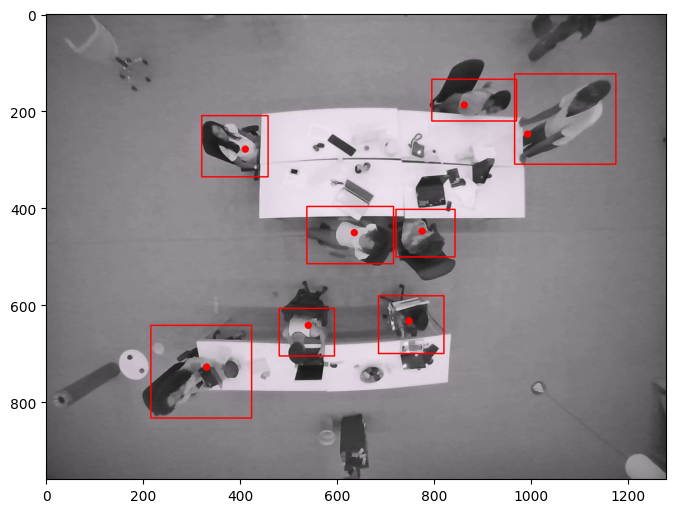

In [43]:
img = cv2.cvtColor(cv2.imread(tst_img_paths[100]), cv2.COLOR_BGR2RGB)

ORIGINAL_H, ORIGIAL_W, _ = img.shape
W = H = 256
RATIO = W / ORIGIAL_W
RESIZED_H = int(ORIGINAL_H * RATIO)
IMG_SHAPE = (1, H, W, 3)
TORCH_IMG_SHAPE = (1, 3, H, W)

conf = 0.1
iou = 0.7
agnostic_nms = False
max_det = 300
classes =None
############################

# Initialize the interpreter
interpreter = tf.lite.Interpreter(
    model_path=f"../../researches/leg_position_detectors/yolov8/run_results/model_1_1m_params/positiondb_pose_1m_{W}/weights/best_saved_model/best_full_integer_quant.tflite")
    #  model_path=f"../../researches/leg_position_detectors/yolov8/run_results/model_2_5m_params/{W}/weights/best_saved_model/best_full_integer_quant.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

im = np.zeros(IMG_SHAPE, dtype=np.uint8)

resized_img = cv2.resize(img, (W, RESIZED_H))
im[0, :RESIZED_H, :W, :] = resized_img[:, :, :]

details = input_details[0]
interpreter.set_tensor(details['index'], im)
interpreter.invoke()
y = []
for output in output_details:
    x = interpreter.get_tensor(output['index'])
    scale, zero_point = output['quantization']
    x = (x.astype(np.float32) - zero_point) * scale  # re-scale

    y.append(x)

y = [x if isinstance(x, np.ndarray) else x.numpy() for x in y]

head = DetectionHead([i.shape for i in y], W)


# Initialize the interpreter
interpreter_head = tf.lite.Interpreter(
  model_path=f"saved_model/head_256_float32.tflite")
interpreter_head.allocate_tensors()

input_details = interpreter_head.get_input_details()
output_details = interpreter_head.get_output_details()

idxs = [4, 1, 5, 3, 0, 2, 6]
for idx, details in enumerate(input_details):
    interpreter_head.set_tensor(details['index'], y[idx])

interpreter_head.invoke()

outputs = interpreter_head.get_tensor(output_details[0]['index'])

head_outputs = outputs

outputs = np.transpose(outputs, (0, 2, 1))
rows = outputs.shape[1]

boxes = []
scores = []
class_ids = []
kps = []

# Iterate through output to collect bounding boxes, confidence scores, and class IDs
for i in range(rows):
    classes_scores = outputs[0][i][4:5]
    (minScore, maxScore, minClassLoc, (x, maxClassIndex)) = cv2.minMaxLoc(classes_scores)
    if maxScore >= conf:
        box = [
            outputs[0][i][0], # - (0.5 * outputs[0][i][2]),
            outputs[0][i][1], # - (0.5 * outputs[0][i][3]),
            outputs[0][i][2],
            outputs[0][i][3],
        ]
        boxes.append(box)
        scores.append(maxScore)
        class_ids.append(maxClassIndex)
        kps.append(outputs[0][i][5:7])

# Apply NMS (Non-maximum suppression)
result_boxes = cv2.dnn.NMSBoxes(boxes, scores, conf, iou, 0.5)

detections = []

# Iterate through NMS results to draw bounding boxes and labels
for i in range(len(result_boxes)):
    index = result_boxes[i]
    box = boxes[index]
    
    detections.append([*box, scores[index], class_ids[index], *kps[index]])
    
detections = np.array(detections)

for box in detections:
    cv2.rectangle(img, (box[:2] / RATIO).astype(int), ((box[:2].astype(int) + box[2:4]) / RATIO).astype(int) , (255, 0, 0), 2)

for p in detections:
    cv2.circle(img, (p[-2:] // RATIO).astype(int), 4, (255, 0, 0), 5)

plt.figure(figsize=(8, 8))
plt.imshow(img)